In this notebook, I want to implement a simple Multilayer Perceptron similar to Andrej Karpathy's Zero to Hero. I watched that series a while ago, but I want to write this code as much as possible without looking at his work. 

Sketch of the code needed:
- Decide on the architecture: Character-level embeddings, 2 layer perceptron
- Embeddings: Trainable weights that map each character into n dimensions. Need to be paired to a context window: How many characters should the model see?
- Two simple fully connected layers of neurons with activation function (after first layer) and softmax (after second layer). 
- Define backward pass: Either calculate by hand for full model, or define for each step and implement automatic chaining of partial derivatives
- training loop (data prep, batching (maybe not needed at first), forward and backward pass, set learning rate and update weights, store loss history)

Stuff to add:
- Train/Val split
- proper initialization
- Sample generation
- Visualization & Analysis

In [ ]:
# Hyperparameters:
SPLIT_SIZE = 0.8 # % of data used for training
BATCH_SIZE = 128 # how many examples to process at once

EMB_D = 5 # number of embedding dimensions
CONTEXT_SIZE = 3 # how many characters the model sees at once

N_LAYERS = 2 # number of layers in the MLP
HIDDEN_D = 400 # number of neurons in the hidden layer

NUM_ITERATIONS = 200000
LEARNING_RATE = lr = 0.01
LR_DECAY = 0.8

In [49]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import polars as pl
plt.style.use('fivethirtyeight')
sns.set_context('notebook')


In [50]:
# file prep
with open('names.txt') as file:
    names = [line.rstrip() for line in file]
print(len(names))
print(max(len(w) for w in names))
print(names[:8])
    

32033
15
['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']


In [51]:
# build dictionary
chars = set()
for name in names:
    for char in name:
        chars.add(char)
chars.add(".")
chars = list(sorted(chars))
print(f"first 10 chars: {chars[:10]}")
dict_size = len(chars)
print(f"dictionary size: {dict_size}")

encodings = {char : number for number, char in enumerate(chars)}
decodings = {number : char for number, char in enumerate(chars)}
print(f"first 5 encodings: {list(encodings.items())[:5]}")
print(f"first 5 decodings: {list(decodings.items())[:5]}")

first 10 chars: ['.', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i']
dictionary size: 27
first 5 encodings: [('.', 0), ('a', 1), ('b', 2), ('c', 3), ('d', 4)]
first 5 decodings: [(0, '.'), (1, 'a'), (2, 'b'), (3, 'c'), (4, 'd')]


In [74]:
np.random.choice(names)

np.str_('celina')

In [52]:
# Data pipeline and Batching
from itertools import cycle

def load_batch():
    def sample_generator():
        name_loader = cycle(names)
        while True:
            name = "." * CONTEXT_SIZE + next(name_loader) + "."
            for index, _ in enumerate(name[:-CONTEXT_SIZE]):
                yield (name[index:index + CONTEXT_SIZE], name[index + CONTEXT_SIZE])
    
    
    sample = sample_generator()
    while True:
        X_az = []
        Y_az = []
        for _ in range(BATCH_SIZE):
            x, y = next(sample)
            X_az.append(x)
            Y_az.append(y)
        X = np.array([[encodings[char] for char in sample]for sample in X_az])
        Y = np.array([encodings[y] for y in Y_az])
        
        yield (X, Y)

batch_loader = load_batch()

In [53]:
# Initialization

W_emb = np.random.normal(0, 1, size=(dict_size, EMB_D))
W1 = np.random.normal(0, (CONTEXT_SIZE * EMB_D)**-0.5, size=(CONTEXT_SIZE * EMB_D, HIDDEN_D))
b1 = np.zeros((1, W1.shape[1]))
W2 = np.random.normal(0, (2/HIDDEN_D)**0.5, size=(HIDDEN_D, dict_size))
b2 = np.zeros((1, W2.shape[1]))

print(f'W_emb.shape: {W_emb.shape}')
print(f'W1.shape: {W1.shape}')
print(f'b1.shape: {b1.shape}')
print(f'W2.shape: {W2.shape}')
print(f'b2.shape: {b2.shape}')

W_emb.shape: (27, 5)
W1.shape: (15, 400)
b1.shape: (1, 400)
W2.shape: (400, 27)
b2.shape: (1, 27)


## Embeddings
Each character has a specific representation in a latent space of dimension EMB_D. In order to implement this, we first one-hot encode our characters, leading to a block of shape BATCH_SIZE x CONTEXT_SIZE x dict_size.

(Note: I want to stick to the convention of one sample per row, one feature per column. This means, in order to have H = X @ W + b, neurons need to be stacked column-wise in W, which at least gives a nice IN x OUT sizing)


Our one-hot-encoded block is then matrix-multiplied with our embedding matrix, which has dimensions EMB_D x dict_size. 

We have a dictionary size dict_size (27) and we have EMD_D embedding dimensions (2). Our batch size is BATCH_SIZE and our context window is size CONTEXT_SIZE. Since we need to one-hot encode our input chars, this requires one dimension of length dict_size. 


In effect we have two "neurons" for our embeddings (one per hidden dimension). Each neuron takes in dict_size inputs. So our embedding transform size is (EMD_D x dict_size)

Our inputs are three-dimensional: Batch x chars per sample (context length) x One-hot-encodings per char. 

Our outputs are three-dimensional as well, with Batch x context length x embedding dimensions (per char), however we will flatten the last two axes, to get a 2d tensor of form BATCH_SIZE x (CONTEXT_SIZE * EMD_D). In this way we will be able to hand over a nice 2d tensor to our actual MLP layers.

## Forward Pass:

In the forward pass, we implement the following mathematical operations:

### Embeddings:
This is more of a look-up table than a calculation. Still, each character has a specific two-dimensional representation that is learnable. We transform:
$$ X_{B,C,D} * W_{emb} = X_0 $$
with $X_{B,C,D}$ in three dimensions `BATCH_SIZE`, `CONTEXT_SIZE` and `dict_size` and $X_0$ having two dimensions (B and C*D) after concatenating C and D.

### First layer
A simple sum of weights + bias with `HIDDEN_D` neurons. The activation function is Leaky Relu.

### Second Layer
Again a simple linear layer, with `dict_size` outputs. 

### Softmax
$$\hat{Y} = \frac{e^{H_2}}{\sum{e^{H_2}}}$$
For each logit, we exponentiate its raw value, and divide by the sum of all the exponentiated values over the sample.

### Cross-entropy loss
$$ Loss = -\sum{log(\hat{y})}\  where\  \hat{y} = y$$
Here, for every sample, we take negative log of the softmax of the predicted y_hat for the correct y. We sum these losses *over all samples in the batch*.


## Backward Pass
We can backprop through the cross-entropy loss and Softmax in one go with a simple formula familiar from logistic regression: The gradient is equal to the probabilities calculated by the softmax everywhere except for the correct outputs, where the gradient is 1 - the given probability of the model.
For backpropping through the linear layers, X @ W = H is a simple linear combination. To take the derivative of that, we calculate dX = dH @ W.T and dW = X.T @ dH respectively. For the gradients of the bias db we have to account for the broadcasting, so db = dH.sum(axis = 0)

The intuition is: For A @ B = C, in matrix multiplication all contributions are diagonally linked, that is all the entries in column x of A have products with all the entries in row x of B and that’s it. So to calculate the derivative for any cell of A or B we just have to take the corresponding column or row of the other matrix, multiplied with the partial derivative of C that our pair contributes to. Thats it! So for any given cell, we
* determine the corresponding fixed line: The diagonal column/row, that is for column x of A this is row x of B and vice versa
* determine the corresponding line in C by the remaining index of the cell we want to calculate: For A, that is row(A) = row(C), for B it is col(B) = col(C)
* Sum up dc with A/B pairwise for the given lines (take the dot product)
* Or, to simplify the notation we get the matrix multiplication shapes above

We can also just look at the dimensions and see what gets us the right shape from there (although that by itself isn’t a full proof): 

C(m.o) = A(m.n) @ B (n.o)<br>
Therefore,<br>
A(m.n)=C(m.o) @ B.t(o.n) and<br>
B(n.o)=A.t(n.m) @ C(m.o)<br>





## Let's loop

In [54]:
loss_history = []

In [55]:
for iteration in range(NUM_ITERATIONS):
    X, Y = next(batch_loader)
    
    # Forward Pass:
    X_onehot = np.eye(dict_size)[X]
    X0 = (X_onehot @ W_emb).reshape(BATCH_SIZE, CONTEXT_SIZE * EMB_D)
    H1 = X0 @ W1 + b1
    X1 = np.where(H1 > 0, H1, H1 * 0.01)
    H2 = X1 @ W2 + b2
    H2_norm = H2 - np.max(H2, axis=1, keepdims=True)
    Y_hat = np.exp(H2_norm) / np.sum(np.exp(H2_norm), axis=1, keepdims=True)
    
    # Loss calculation:
    loss = np.mean(-np.log(Y_hat[np.arange(BATCH_SIZE), Y]))
    if iteration % 100 == 0:
        loss_history.append(loss)
    if iteration % 10000 == 0:
        print(f'Loss after {iteration} iterations: {loss}. Current learning rate: {lr:.2e}')

    # Adaptive Learning rate 
    # if iteration % 1000 == 0:
    #     if np.sum(loss_history[-100:-50]) < np.sum(loss_history[-50:]):
    #         lr *= LR_DECAY
    if iteration == np.round(0.8 * NUM_ITERATIONS):
        lr /= 6

    # Backward Pass:
    dH2 = Y_hat.copy()
    dH2[np.arange(BATCH_SIZE), Y] -= 1
    dH2 /= BATCH_SIZE

    dX1 = dH2 @ W2.T
    dW2 = X1.T @ dH2
    db2 = dH2.sum(axis=0, keepdims=True)

    dH1 = np.where(H1 > 0, dX1, 0.01 * dX1)

    dX0 = dH1 @ W1.T
    dW1 = X0.T @ dH1
    db1 = dH1.sum(axis=0, keepdims=True)
    dW_emb = (X_onehot.transpose((0, 2, 1)) @ dX0.reshape(BATCH_SIZE, CONTEXT_SIZE, EMB_D)).sum(axis=0)

    # Gradient update:
    W_emb -= lr * dW_emb
    W1 -= lr * dW1
    b1 -= lr * db1
    W2 -= lr * dW2
    b2 -= lr * db2




Loss after 0 iterations: 3.7418124517980793. Current learning rate: 1.00e-02
Loss after 10000 iterations: 2.385229692327578. Current learning rate: 1.00e-02
Loss after 20000 iterations: 2.165082802063157. Current learning rate: 1.00e-02
Loss after 30000 iterations: 2.5870306102516585. Current learning rate: 1.00e-02
Loss after 40000 iterations: 1.870512601575165. Current learning rate: 1.00e-02
Loss after 50000 iterations: 2.109669419091709. Current learning rate: 1.00e-02
Loss after 60000 iterations: 2.271396785731723. Current learning rate: 1.00e-02
Loss after 70000 iterations: 2.2583853900275646. Current learning rate: 1.00e-02
Loss after 80000 iterations: 2.2044772369513463. Current learning rate: 1.00e-02
Loss after 90000 iterations: 2.1080739595343965. Current learning rate: 1.00e-02
Loss after 100000 iterations: 1.789850486680332. Current learning rate: 1.00e-02
Loss after 110000 iterations: 2.396827908806843. Current learning rate: 1.00e-02
Loss after 120000 iterations: 2.25789

(<Axes: >, np.float64(2.093088263142323))

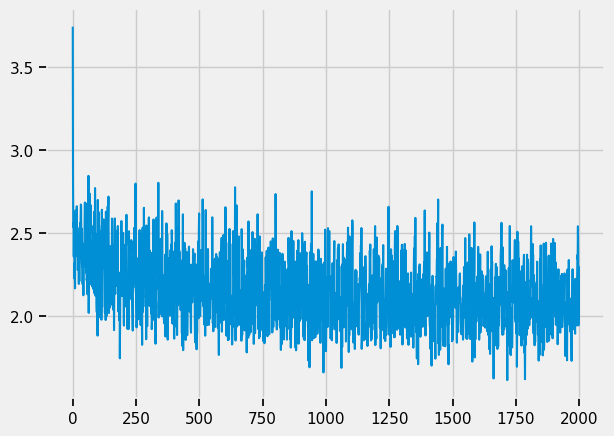

In [56]:
sns.lineplot(loss_history), np.mean(loss_history[int(len(loss_history)*0.9):])

## Logbook:
### First version:
BATCH_SIZE = 64 # how many examples to process at once  
EMB_D = 2 # number of embedding dimensions  
CONTEXT_SIZE = 3 # how many characters the model sees at once  
N_LAYERS = 2 # number of layers in the MLP  
HIDDEN_D = 30 # number of neurons in the hidden layer  
Loss after a few hundred thousand passes: 2.695

### Second version:
>BATCH_SIZE = 64 # how many examples to process at once
EMB_D = 4 # number of embedding dimensions
CONTEXT_SIZE = 3 # how many characters the model sees at once
N_LAYERS = 2 # number of layers in the MLP
HIDDEN_D = 300 # number of neurons in the hidden layer
Loss after 300k: 2.63

### Third version:
Bug fixed: W1 and b1 now learn  
BATCH_SIZE = 128 # how many examples to process at once  
EMB_D = 7 # number of embedding dimensions  
CONTEXT_SIZE = 3 # how many characters the model sees at once  
N_LAYERS = 2 # number of layers in the MLP  
HIDDEN_D = 600 # number of neurons in the hidden layer  
Loss:  2.59

### Fourth version:
Improved initialization (He/Kaiming-style), increased learning rate and softened lr decay, chose hyperparameters similar to Andrej Karpathy. Increased learning rate led to big gains  
BATCH_SIZE = 128 # how many examples to process at once  
EMB_D = 5 # number of embedding dimensions  
CONTEXT_SIZE = 3 # how many characters the model sees at once  
N_LAYERS = 2 # number of layers in the MLP  
HIDDEN_D = 400 # number of neurons in the hidden layer  
NUM_ITERATIONS = 100000  
LEARNING_RATE = lr = 1e-2    
LR_DECAY = 0.9  
Loss: 2.16

### Fifth version:
simpler adaptive learning rate, up to 200,000 batches. Generated samples look...more complicated and consonant-y than previously, perhaps overfitting starting? Can't test until I implement train/test split
Learning rate = 0.01, divided by 6 for last 20% of training
Loss: 2.09

Training takes 1min 12sec on my laptop

In [60]:
# Generate:
def predict(context):
    if len(context) != CONTEXT_SIZE:
        return None
    x = [encodings[char] for char in context]
    X_onehot = np.eye(dict_size)[x]
    X0 = (X_onehot @ W_emb).reshape(CONTEXT_SIZE * EMB_D)
    H1 = X0 @ W1 + b1
    X1 = np.where(H1 > 0, H1, H1 * 0.01)
    H2 = X1 @ W2 + b2
    H2_norm = H2 - np.max(H2, axis=1, keepdims=True)
    Y_hat = np.exp(H2_norm) / np.sum(np.exp(H2_norm), axis=1, keepdims=True)
    return np.random.choice(chars, p = Y_hat.squeeze())

In [64]:
for _ in range(20):
    name = '...'
    while True:
        name += predict(name[-CONTEXT_SIZE:])
        if name[-1] == '.':
            print(name[CONTEXT_SIZE:-1])
            break

athriyana
malejani
pyaire
kayli
kamby
arricite
adeliateel
selima
iyjiosiionne
yuzanio
ahiena
runxya
cariyahta
mirin
dari
katai
lani
lillaiya
rier
oston


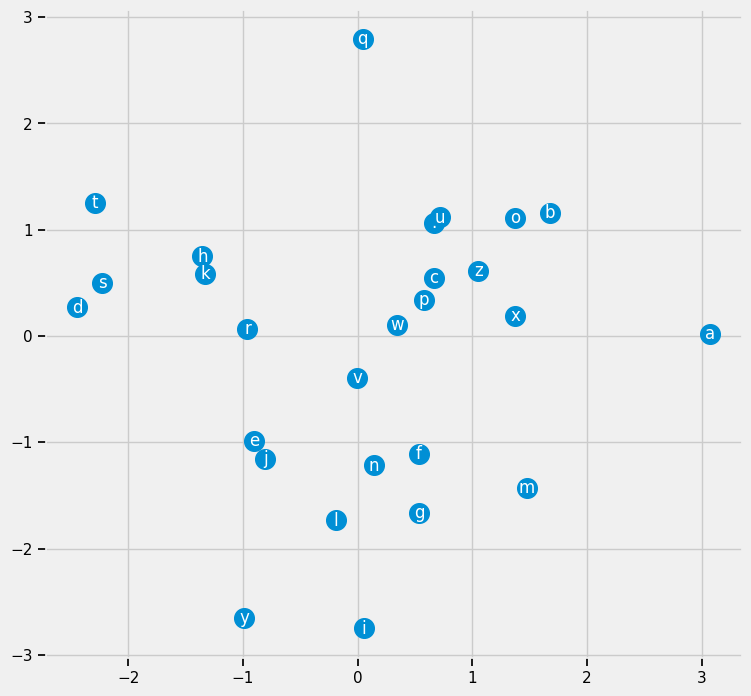

In [62]:
# visualize dimensions 0 and 1 of the embedding matrix for all characters; code copied from Andrej Karpathy
plt.figure(figsize=(8,8))
plt.scatter(W_emb[:,0].data, W_emb[:,1].data, s=200)
for i in range(W_emb.shape[0]):
    plt.text(W_emb[i,0].item(), W_emb[i,1].item(), decodings[i], ha="center", va="center", color='white')
plt.grid('minor')